# LunarLander-v3：DQN 抗風能力研究（老師第三章 Listing 3.7 延伸）

## 作業內容
1. 建立原始 DQN（8→150→100→4、Experience Replay、Target Network）。
2. 優先載入你已訓練的 `lunarlander_dqn.pth`；找不到才訓練無風基準模型。
3. 從基準模型出發，在無風／微風／強風的混合環境繼續訓練「抗風 DQN」。
4. 兩個模型都在相同的三種測試環境、相同 seeds 下評估。
5. 輸出 Reward 比較圖、CSV，以及 VS Code Notebook 可觀看的 GIF。

**請注意**：在先前訓練模型的 Notebook 執行
`torch.save(model.state_dict(), 'lunarlander_dqn.pth')`，
並將該檔放在本程式執行時的工作資料夾，才能沿用舊成果。
若原模型存在但不相容，會顯示錯誤，請不要直接改用隨機模型當作「訓練完成」。

首次安裝（在 VS Code Notebook 中執行）：
`%pip install "gymnasium[box2d]" torch numpy matplotlib pillow`

來源：Chapter 3 Listing 3.7 DQN + Target Network；
Gymnasium LunarLander-v3 官方 wind 設定。

In [19]:
from pathlib import Path
from collections import deque
import copy
import csv
import random

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image as PILImage, ImageDraw
from IPython.display import Image as NotebookImage, display

## 0. 主要設定（想簡化作業就從這裡調整）

**保留原有模型最重要**：`baseline_path` 指向先前存好的 `.pth`；
已經存在就不會重訓原始 800 回合。

`RUN_WIND_FINETUNE=True`：訓練抗風版本。若抗風模型檔已存在，會直接載入。
`FORCE_RETRAIN_WIND=True`：忽略之前的抗風模型，重新進行抗風微調。

抗風微調是在「原始已訓練模型」上額外訓練，並非同等回合數從零開始訓練；
報告應如實寫出這個差異。

In [20]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUTPUT_DIR = Path.cwd() / "lunarlander_wind_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_PATH = Path.cwd() / "lunarlander_dqn.pth"   # 與以前 Notebook 儲存的檔名相同
BASELINE_NEW_PATH = OUTPUT_DIR / "dqn_baseline.pth"
WIND_MODEL_PATH = OUTPUT_DIR / "dqn_wind_finetuned.pth"

BASELINE_EPISODES = 800      # 只有沒有舊模型時才會進行
WIND_FINETUNE_EPISODES = 300 # 已訓練好的 DQN 加做 300 回合混合風力訓練
TEST_EPISODES = 20           # 每個模型 x 每種風力的測試次數
RUN_WIND_FINETUNE = True
FORCE_RETRAIN_WIND = False
MAKE_GIFS = True

LEARNING_RATE = 1e-3
GAMMA = 0.99
MEMORY_SIZE = 50000
BATCH_SIZE = 64
SYNC_FREQ = 500
MAX_STEPS = 1000

# Gymnasium 官方支援的風力參數；以下是本作業自行定義的三種難度。
WIND_SETTINGS = {
    "No Wind": {"enable_wind": False},
    "Light Wind": {"enable_wind": True, "wind_power": 5.0, "turbulence_power": 0.5},
    "Strong Wind": {"enable_wind": True, "wind_power": 15.0, "turbulence_power": 1.5},
}

print("工作資料夾:", Path.cwd())
print("輸出資料夾:", OUTPUT_DIR)
print("現有原始模型:", BASELINE_PATH.exists())

工作資料夾: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告
輸出資料夾: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_wind_results
現有原始模型: True


## 1. 遊戲環境與 DQN 神經網路

延續Listing 3.7 的 `torch.nn.Sequential`，保留兩個隱藏層
150、100 個神經元、Adam、MSELoss、Replay Buffer、Target Network。
LunarLander 將輸入由 64 維改成 8 維，輸出 4 個離散動作。

In [21]:
probe_env = gym.make("LunarLander-v3")
state_dim = probe_env.observation_space.shape[0]
action_dim = probe_env.action_space.n
probe_env.close()
assert state_dim == 8 and action_dim == 4, "這份程式適用 LunarLander-v3 離散動作版（8 狀態、4 動作）"
print(f"狀態數：{state_dim}；動作數：{action_dim}")


def create_model():
    return torch.nn.Sequential(
        torch.nn.Linear(state_dim, 150),
        torch.nn.ReLU(),
        torch.nn.Linear(150, 100),
        torch.nn.ReLU(),
        torch.nn.Linear(100, action_dim),
    )


def load_weights(model, path):
    # weights_only=True：只讀取權重，不載入任意 Python 物件
    state_dict = torch.load(path, map_location="cpu", weights_only=True)
    model.load_state_dict(state_dict)
    return model

狀態數：8；動作數：4


## 2. DQN 訓練函式

用 `epsilon-greedy` 探索、Replay Buffer 儲存 `(s,a,r,s',terminated)`，
每個環境步數更新 Q 網路，並定期同步 Target Network。
注意 `truncated`（時間限制）要結束回合，但 Bellman target 只因真正
`terminated` 停止 bootstrap。

In [22]:
def train_dqn(model, episodes, wind_mixture, epsilon_start, epsilon_decay, label):
    # 每一個 scenario 建一次環境；每回合選擇一個，再 reset。
    training_envs = {name: gym.make("LunarLander-v3", **WIND_SETTINGS[name])
                     for name in wind_mixture}
    model2 = copy.deepcopy(model)  # 老師 Listing 3.7：Target network
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = torch.nn.MSELoss()
    replay = deque(maxlen=MEMORY_SIZE)

    episode_rewards = []
    losses = []
    epsilon = epsilon_start
    total_steps = 0
    model.train()

    try:
        for ep in range(episodes):
            # 每回合使用一個難度：抗風微調時混合無風與有風環境。
            scenario = random.choice(wind_mixture)
            env = training_envs[scenario]
            state, _ = env.reset(seed=SEED + 10000 + ep)
            episode_reward = 0.0

            for t in range(MAX_STEPS):
                total_steps += 1
                if random.random() < epsilon:
                    action = random.randrange(action_dim)
                else:
                    with torch.no_grad():
                        x = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
                        action = int(model(x).argmax(dim=1).item())

                next_state, reward, terminated, truncated, _ = env.step(action)
                replay.append((np.array(state, copy=True), action, float(reward),
                               np.array(next_state, copy=True), float(terminated)))
                state = next_state
                episode_reward += float(reward)

                if len(replay) >= BATCH_SIZE:
                    minibatch = random.sample(replay, BATCH_SIZE)
                    states = torch.as_tensor(np.array([v[0] for v in minibatch]), dtype=torch.float32)
                    actions = torch.as_tensor([v[1] for v in minibatch], dtype=torch.long)
                    rewards = torch.as_tensor([v[2] for v in minibatch], dtype=torch.float32)
                    next_states = torch.as_tensor(np.array([v[3] for v in minibatch]), dtype=torch.float32)
                    terminals = torch.as_tensor([v[4] for v in minibatch], dtype=torch.float32)

                    q_pred = model(states).gather(1, actions.unsqueeze(1)).squeeze(1)
                    with torch.no_grad():
                        q_next = model2(next_states).max(dim=1).values
                        q_target = rewards + GAMMA * (1.0 - terminals) * q_next

                    loss = loss_fn(q_pred, q_target)
                    optimizer.zero_grad()
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
                    optimizer.step()
                    losses.append(float(loss.item()))

                if total_steps % SYNC_FREQ == 0:
                    model2.load_state_dict(model.state_dict())

                if terminated or truncated:
                    break

            episode_rewards.append(episode_reward)
            epsilon = max(0.05, epsilon * epsilon_decay)
            if (ep + 1) % 20 == 0 or ep == 0:
                avg = np.mean(episode_rewards[-20:])
                print(f"{label} {ep + 1:4d}/{episodes} | {scenario:11s} | "
                      f"reward={episode_reward:8.1f} | recent20={avg:8.1f} | eps={epsilon:.3f}")
    finally:
        for env in training_envs.values():
            env.close()

    return episode_rewards, losses

## 3. 載入舊模型（或必要時訓練無風基準模型）

如你已在舊 Notebook 完成 800 回合，**先在舊 Notebook 儲存**：
`torch.save(model.state_dict(), 'lunarlander_dqn.pth')`

如果這個 `.pth` 在不同資料夾，請修改上面的 `BASELINE_PATH`。

In [23]:
baseline_model = create_model()
baseline_rewards = []
baseline_losses = []
if BASELINE_PATH.is_file():
    load_weights(baseline_model, BASELINE_PATH)
    print("已載入之前訓練完成的原始 DQN，不重訓！", BASELINE_PATH)
elif BASELINE_NEW_PATH.is_file():
    load_weights(baseline_model, BASELINE_NEW_PATH)
    print("已載入本作業之前訓練的無風基準 DQN：", BASELINE_NEW_PATH)
else:
    print("找不到原始模型檔，開始訓練無風基準 DQN。")
    baseline_rewards, baseline_losses = train_dqn(
        baseline_model, episodes=BASELINE_EPISODES,
        wind_mixture=["No Wind"], epsilon_start=1.0,
        epsilon_decay=0.995, label="Baseline"
    )
    torch.save(baseline_model.state_dict(), BASELINE_NEW_PATH)
    print("基準模型已存至:", BASELINE_NEW_PATH)

已載入之前訓練完成的原始 DQN，不重訓！ c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_dqn.pth


## 4. 創意改良：混合風力環境微調（Wind Fine-tuning）

從同一份原始模型權重出發，在不同風力下繼續學習。
這是額外訓練，不能宣稱與原始模型有完全相同的訓練預算。
因為神經網路沒有額外加入風速感測器，它只能依 8 個狀態學習抗干擾反應。

In [24]:
wind_model = copy.deepcopy(baseline_model)
wind_rewards = []
wind_losses = []
if WIND_MODEL_PATH.is_file() and not FORCE_RETRAIN_WIND:
    load_weights(wind_model, WIND_MODEL_PATH)
    print("已載入上次訓練好的抗風模型，不需再次微調。")
elif RUN_WIND_FINETUNE:
    print("開始風力微調：無風/微風/強風混合訓練。")
    wind_rewards, wind_losses = train_dqn(
        wind_model, episodes=WIND_FINETUNE_EPISODES,
        wind_mixture=["No Wind", "Light Wind", "Strong Wind"],
        epsilon_start=0.30, epsilon_decay=0.99, label="Wind-tune"
    )
    torch.save(wind_model.state_dict(), WIND_MODEL_PATH)
    print("抗風模型已存至:", WIND_MODEL_PATH)
else:
    print("沒有執行抗風微調；目前 wind_model 與 baseline_model 相同。")

開始風力微調：無風/微風/強風混合訓練。
Wind-tune    1/300 | Strong Wind | reward=   168.9 | recent20=   168.9 | eps=0.297
Wind-tune   20/300 | Light Wind  | reward=   -41.4 | recent20=    24.6 | eps=0.245
Wind-tune   40/300 | Strong Wind | reward=   -32.8 | recent20=    -3.9 | eps=0.201
Wind-tune   60/300 | Light Wind  | reward=   -12.8 | recent20=    -6.8 | eps=0.164
Wind-tune   80/300 | Strong Wind | reward=   -85.8 | recent20=    39.5 | eps=0.134
Wind-tune  100/300 | Strong Wind | reward=   298.5 | recent20=   141.0 | eps=0.110
Wind-tune  120/300 | No Wind     | reward=   267.5 | recent20=   125.2 | eps=0.090
Wind-tune  140/300 | Light Wind  | reward=   224.8 | recent20=   150.9 | eps=0.073
Wind-tune  160/300 | No Wind     | reward=   271.3 | recent20=   169.2 | eps=0.060
Wind-tune  180/300 | Strong Wind | reward=     2.8 | recent20=   138.5 | eps=0.050
Wind-tune  200/300 | No Wind     | reward=   277.3 | recent20=   225.2 | eps=0.050
Wind-tune  220/300 | Strong Wind | reward=   244.4 | recent20=   1

## 5. 固定種子、三種風力、公平測試

每個模型都在三種環境跑相同的 20 個 seeds，不使用 epsilon 隨機探索。
報告項目：平均 Reward、標準差、達到 >=200 分的回合數、主引擎使用率。
**>=200 分只是回合分數門檻，不是精確的安全著陸次數。**

In [25]:
def evaluate(model, env_kwargs, seeds):
    env = gym.make("LunarLander-v3", **env_kwargs)
    scores = []
    main_engine_steps = 0
    all_steps = 0
    model.eval()
    try:
        for seed in seeds:
            state, _ = env.reset(seed=int(seed))
            score = 0.0
            for _ in range(MAX_STEPS):
                with torch.no_grad():
                    x = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
                    action = int(model(x).argmax(dim=1).item())
                main_engine_steps += (action == 2)
                all_steps += 1
                state, reward, terminated, truncated, _ = env.step(action)
                score += float(reward)
                if terminated or truncated:
                    break
            scores.append(score)
    finally:
        env.close()
    scores = np.asarray(scores, dtype=float)
    return {
        "mean_reward": float(scores.mean()),
        "std_reward": float(scores.std()),
        "score_200_count": int(np.sum(scores >= 200)),
        "main_engine_pct": float(100.0 * main_engine_steps / max(all_steps, 1)),
        "scores": scores.tolist(),
    }


SEEDS = [3000 + i for i in range(TEST_EPISODES)]
models = {"Original DQN": baseline_model}
if RUN_WIND_FINETUNE or WIND_MODEL_PATH.is_file():
    models["Wind-finetuned DQN"] = wind_model

comparison = {}
for model_name, current_model in models.items():
    for condition, kwargs in WIND_SETTINGS.items():
        summary = evaluate(current_model, kwargs, SEEDS)
        comparison[(model_name, condition)] = summary
        print(f"{model_name:19s} | {condition:11s} | "
              f"Mean {summary['mean_reward']:8.1f} ± {summary['std_reward']:7.1f} | "
              f">=200: {summary['score_200_count']:2d}/{TEST_EPISODES} | "
              f"main engine {summary['main_engine_pct']:5.1f}%")

csv_path = OUTPUT_DIR / "wind_comparison.csv"
with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["model", "wind_condition", "mean_reward", "std_reward",
                     "score_ge_200_count", "test_episodes", "main_engine_pct"])
    for (name, condition), stats in comparison.items():
        writer.writerow([name, condition, stats["mean_reward"], stats["std_reward"],
                         stats["score_200_count"], TEST_EPISODES, stats["main_engine_pct"]])
print("CSV 已儲存:", csv_path)

Original DQN        | No Wind     | Mean    161.3 ±   137.9 | >=200: 11/20 | main engine  33.2%
Original DQN        | Light Wind  | Mean    189.5 ±   149.2 | >=200: 15/20 | main engine  33.3%
Original DQN        | Strong Wind | Mean     95.5 ±   171.7 | >=200:  9/20 | main engine  29.1%
Wind-finetuned DQN  | No Wind     | Mean    189.5 ±   181.7 | >=200: 17/20 | main engine  33.1%
Wind-finetuned DQN  | Light Wind  | Mean    182.6 ±   181.3 | >=200: 15/20 | main engine  25.8%
Wind-finetuned DQN  | Strong Wind | Mean    107.9 ±   197.2 | >=200: 12/20 | main engine  34.1%
CSV 已儲存: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_wind_results\wind_comparison.csv


## 6. 畫出訓練曲線和抗風比較圖

長條顯示平均 Reward，誤差線顯示各回合 Reward 的標準差。
如果有從既有 checkpoint 載入模型，就不會有該模型過去 800 回合的曲線。

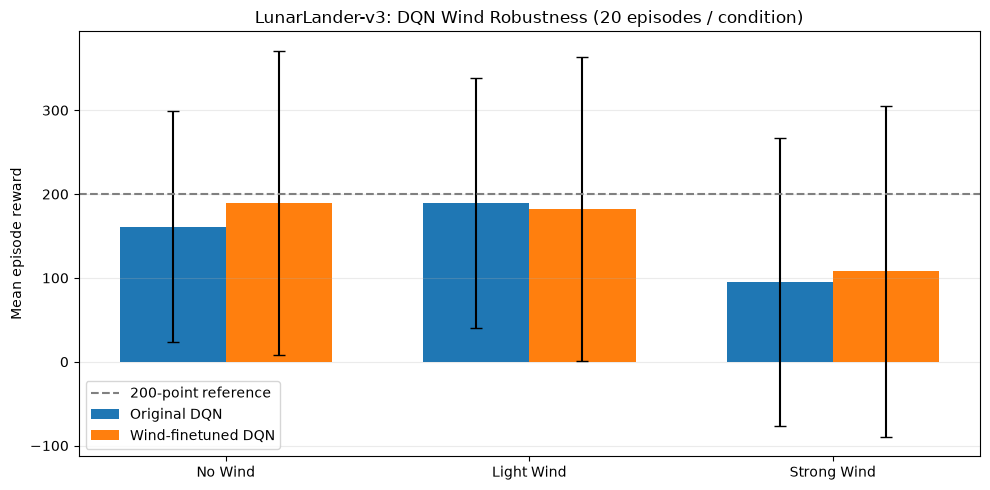

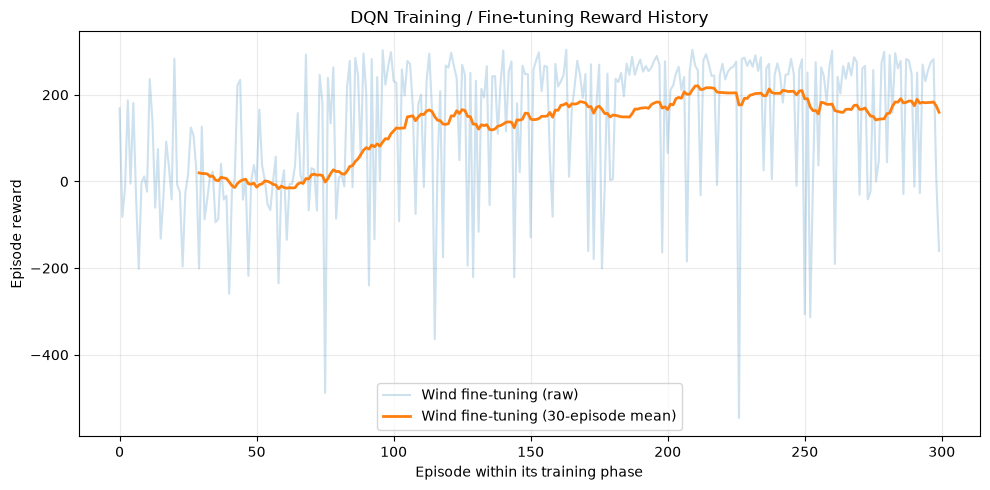

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
conditions = list(WIND_SETTINGS)
x = np.arange(len(conditions))
bar_width = 0.35
for idx, model_name in enumerate(models):
    means = [comparison[(model_name, c)]["mean_reward"] for c in conditions]
    stds = [comparison[(model_name, c)]["std_reward"] for c in conditions]
    positions = x + (idx - (len(models) - 1) / 2) * bar_width
    ax.bar(positions, means, bar_width, yerr=stds, capsize=4, label=model_name)
ax.set_xticks(x, conditions)
ax.axhline(200, linestyle="--", color="gray", label="200-point reference")
ax.set_ylabel("Mean episode reward")
ax.set_title(f"LunarLander-v3: DQN Wind Robustness ({TEST_EPISODES} episodes / condition)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "wind_reward_comparison.png", dpi=160)
plt.show()

if baseline_rewards or wind_rewards:
    fig, ax = plt.subplots(figsize=(10, 5))
    for name, rewards in [("Baseline training", baseline_rewards),
                          ("Wind fine-tuning", wind_rewards)]:
        if not rewards:
            continue
        scores = np.asarray(rewards, dtype=float)
        ax.plot(scores, alpha=0.22, label=f"{name} (raw)")
        if len(scores) >= 30:
            moving = np.convolve(scores, np.ones(30) / 30, mode="valid")
            ax.plot(np.arange(29, len(scores)), moving, linewidth=2,
                    label=f"{name} (30-episode mean)")
    ax.set_title("DQN Training / Fine-tuning Reward History")
    ax.set_xlabel("Episode within its training phase")
    ax.set_ylabel("Episode reward")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "training_reward_history.png", dpi=160)
    plt.show()

## 7. 錄製遊戲 GIF（不用再開跳不出來的 human 視窗）

使用 `render_mode="rgb_array"` 取得每個畫面，存成 GIF。
會產生原始 DQN 強風、抗風 DQN 強風，及抗風 DQN 無風三個示範動畫。
**GIF 是實際模型操作結果，不保證每次都成功降落。**

Original DQN / Strong Wind | Reward=198.7 | GIF: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_wind_results\original_dqn_strong_wind.gif
Wind-tuned DQN / Strong Wind | Reward=226.1 | GIF: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_wind_results\finetuned_dqn_strong_wind.gif
Wind-tuned DQN / No Wind | Reward=306.5 | GIF: c:\Users\ASUS Vivobook\Desktop\深度強化學習報告\lunarlander_wind_results\finetuned_dqn_no_wind.gif
播放: original_dqn_strong_wind.gif


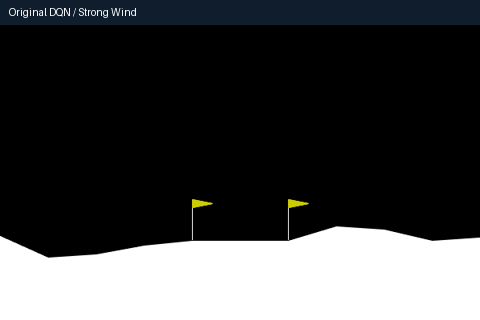

播放: finetuned_dqn_strong_wind.gif


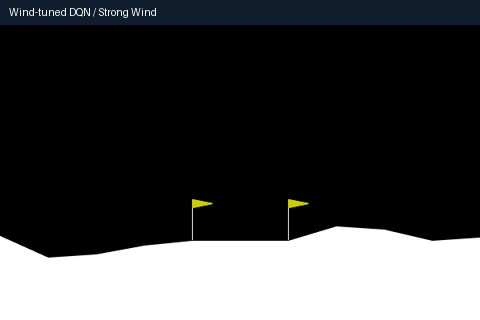

播放: finetuned_dqn_no_wind.gif


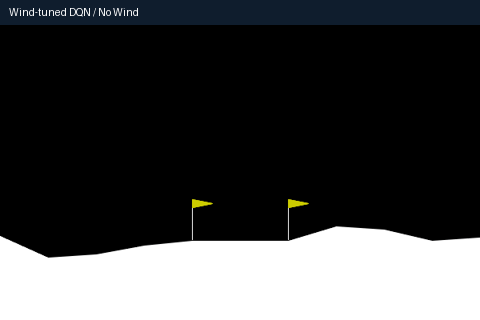

In [12]:
def save_game_gif(model, env_kwargs, filename, title, seed=3000):
    env = gym.make("LunarLander-v3", render_mode="rgb_array", **env_kwargs)
    frames = []
    state, _ = env.reset(seed=seed)
    model.eval()
    score = 0.0
    try:
        # 第 0 幀，讓觀察者看到初始狀態
        for step in range(MAX_STEPS):
            if step % 3 == 0:
                raw_frame = env.render()
                image = PILImage.fromarray(raw_frame).convert("RGB")
                image = image.resize((480, 320))
                overlay = ImageDraw.Draw(image)
                overlay.rectangle((0, 0, 480, 24), fill=(15, 29, 45))
                overlay.text((9, 6), title, fill=(255, 255, 255))
                frames.append(image)

            with torch.no_grad():
                x = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
                action = int(model(x).argmax(dim=1).item())
            state, reward, terminated, truncated, _ = env.step(action)
            score += float(reward)
            if terminated or truncated:
                break

        last = PILImage.fromarray(env.render()).convert("RGB").resize((480, 320))
        overlay = ImageDraw.Draw(last)
        overlay.rectangle((0, 0, 480, 26), fill=(15, 29, 45))
        overlay.text((9, 6), f"{title} | Reward {score:.1f}", fill=(255, 255, 255))
        frames.extend([last] * 8)
    finally:
        env.close()

    file_path = OUTPUT_DIR / filename
    frames[0].save(file_path, save_all=True, append_images=frames[1:],
                   duration=60, loop=0, optimize=True)
    print(f"{title} | Reward={score:.1f} | GIF: {file_path}")
    return file_path

if MAKE_GIFS:
    gifs = [save_game_gif(baseline_model, WIND_SETTINGS["Strong Wind"],
                          "original_dqn_strong_wind.gif", "Original DQN / Strong Wind")]
    if "Wind-finetuned DQN" in models:
        gifs += [save_game_gif(wind_model, WIND_SETTINGS["Strong Wind"],
                               "finetuned_dqn_strong_wind.gif", "Wind-tuned DQN / Strong Wind"),
                 save_game_gif(wind_model, WIND_SETTINGS["No Wind"],
                               "finetuned_dqn_no_wind.gif", "Wind-tuned DQN / No Wind")]
    # 直接在 VS Code Notebook 輸出格顯示，與外部 pygame 視窗無關。
    for gif_file in gifs:
        print("播放:", gif_file.name)
        display(NotebookImage(filename=str(gif_file)))



官方環境文件：https://gymnasium.farama.org/environments/box2d/lunar_lander/